In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import time
import heapq
from pathlib import Path

# Locate the project directory
PROJECT_DIR = Path.cwd()

# Load the datasets
parcels = pd.read_csv(PROJECT_DIR / "datasets" / "parcels.csv")
roads = pd.read_csv(PROJECT_DIR / "datasets" / "roads.csv")

print("MINI-COURIER PLANNER")
print("=" * 35)

print("\nParcel Dataset:")
display(parcels)

print("\nRoad Dataset:")
display(roads)

print("\nTotal parcels:", len(parcels))
print("Total roads:", len(roads))

MINI-COURIER PLANNER

Parcel Dataset:


,ParcelID,Weight,Priority,Deadline,Value,Location
0,P1,4,5,10:00,80,A
1,P2,3,4,11:00,60,B
2,P3,5,3,12:00,100,C
3,P4,2,5,09:30,50,D
4,P5,6,2,13:00,120,A
5,P6,1,4,10:30,40,C
6,P7,3,3,11:30,70,B
7,P8,4,1,14:00,90,D



Road Dataset:


,From,To,Distance
0,Depot,A,4
1,Depot,B,7
2,A,B,2
3,A,C,5
4,B,C,3
5,B,D,6
6,C,D,2



Total parcels: 8
Total roads: 7


In [2]:

# PHASE 2: PARCEL PRIORITIZATION USING MERGE SORT

def merge_sort_parcels(parcel_list):
    """
    Sort parcels by:
    1. Higher priority first
    2. Earlier deadline first when priorities are equal
    """

    # Base case: a list with 0 or 1 item is already sorted
    if len(parcel_list) <= 1:
        return parcel_list

    # Divide the list into two halves
    middle = len(parcel_list) // 2

    left_half = merge_sort_parcels(parcel_list[:middle])
    right_half = merge_sort_parcels(parcel_list[middle:])

    # Merge both sorted halves
    return merge_parcels(left_half, right_half)


def merge_parcels(left, right):
    """Merge two sorted parcel lists into one sorted list."""

    result = []
    i = 0
    j = 0

    while i < len(left) and j < len(right):

        left_parcel = left[i]
        right_parcel = right[j]

        # Higher priority first; earlier deadline breaks ties
        left_key = (
            -int(left_parcel["Priority"]),
            left_parcel["Deadline"]
        )

        right_key = (
            -int(right_parcel["Priority"]),
            right_parcel["Deadline"]
        )

        if left_key <= right_key:
            result.append(left_parcel)
            i += 1
        else:
            result.append(right_parcel)
            j += 1

    # Append any remaining parcels
    result.extend(left[i:])
    result.extend(right[j:])

    return result


# Convert the DataFrame into a list of parcel records
parcel_records = parcels.to_dict("records")

# Run Merge Sort and measure its execution time
start_time = time.perf_counter()

sorted_parcels = merge_sort_parcels(parcel_records)

sorting_time = time.perf_counter() - start_time

# Display the sorted parcels
sorted_parcels_df = pd.DataFrame(sorted_parcels)

print("SORTED PARCELS")
display(
    sorted_parcels_df[
        ["ParcelID", "Priority", "Deadline", "Weight", "Value", "Location"]
    ]
)

print(f"Sorting runtime: {sorting_time:.8f} seconds")


SORTED PARCELS


,ParcelID,Priority,Deadline,Weight,Value,Location
0,P4,5,09:30,2,50,D
1,P1,5,10:00,4,80,A
2,P6,4,10:30,1,40,C
3,P2,4,11:00,3,60,B
4,P7,3,11:30,3,70,B
5,P3,3,12:00,5,100,C
6,P5,2,13:00,6,120,A
7,P8,1,14:00,4,90,D


Sorting runtime: 0.00011060 seconds


In [3]:

# PHASE 2: PARCEL PACKING USING 0/1 KNAPSACK DP

def knapsack_dp(parcel_list, capacity):
    """
    Select parcels with maximum total value without
    exceeding the van's capacity.

    Each parcel can be selected at most once.
    """

    n = len(parcel_list)

    # dp[i][w] = maximum value using the first i parcels
    # with capacity w
    dp = [[0] * (capacity + 1) for _ in range(n + 1)]

    # Build the DP table
    for i in range(1, n + 1):
        parcel = parcel_list[i - 1]

        weight = int(parcel["Weight"])
        value = int(parcel["Value"])

        for w in range(capacity + 1):

            # Option 1: Do not select this parcel
            dp[i][w] = dp[i - 1][w]

            # Option 2: Select it if it fits
            if weight <= w:
                candidate = value + dp[i - 1][w - weight]

                if candidate > dp[i][w]:
                    dp[i][w] = candidate

    # Backtrack through the DP table to find selected parcels
    selected = []
    remaining_capacity = capacity

    for i in range(n, 0, -1):
        if dp[i][remaining_capacity] != dp[i - 1][remaining_capacity]:

            parcel = parcel_list[i - 1]
            selected.append(parcel)

            remaining_capacity -= int(parcel["Weight"])

    selected.reverse()

    return selected, dp


# Set the van's capacity
VAN_CAPACITY = 10

# Run the algorithm and measure its runtime
start_time = time.perf_counter()

selected_parcels, dp_table = knapsack_dp(
    sorted_parcels,
    VAN_CAPACITY
)

knapsack_time = time.perf_counter() - start_time

# Display selected parcels
selected_df = pd.DataFrame(selected_parcels)

print("OPTIMAL PACKING PLAN")
print("=" * 35)

display(selected_df[
    ["ParcelID", "Weight", "Value", "Location"]
].to_string(index=False))

total_weight = sum(int(p["Weight"]) for p in selected_parcels)
total_value = sum(int(p["Value"]) for p in selected_parcels)

print("\nVan capacity:", VAN_CAPACITY)
print("Total selected weight:", total_weight)
print("Remaining capacity:", VAN_CAPACITY - total_weight)
print("Total selected value:", total_value)
print(f"Knapsack runtime: {knapsack_time:.8f} seconds")

# Display the DP table
dp_df = pd.DataFrame(
    dp_table,
    columns=range(VAN_CAPACITY + 1)
)

print("\nDYNAMIC PROGRAMMING TABLE")
display(dp_df)


OPTIMAL PACKING PLAN


'ParcelID  Weight  Value Location\n      P4       2     50        D\n      P6       1     40        C\n      P7       3     70        B\n      P8       4     90        D'


Van capacity: 10
Total selected weight: 10
Remaining capacity: 0
Total selected value: 250
Knapsack runtime: 0.00014400 seconds

DYNAMIC PROGRAMMING TABLE


,0,1,2,3,4,5,6,7,8,9,10
0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,50,50,50,50,50,50,50,50,50
2,0,0,50,50,80,80,130,130,130,130,130
3,0,40,50,90,90,120,130,170,170,170,170
4,0,40,50,90,100,120,150,170,180,190,230
5,0,40,50,90,110,120,160,170,190,220,240
6,0,40,50,90,110,120,160,170,190,220,240
7,0,40,50,90,110,120,160,170,190,220,240
8,0,40,50,90,110,130,160,180,200,220,250


In [4]:

# PHASE 3: BUILD THE COURIER ROAD GRAPH

graph = {}

for _, road in roads.iterrows():
    source = road["From"]
    destination = road["To"]
    distance = float(road["Distance"])

    # Add both directions because roads are bidirectional
    graph.setdefault(source, {})[destination] = distance
    graph.setdefault(destination, {})[source] = distance

print("COURIER ROAD GRAPH")
print("=" * 35)

for location, neighbors in graph.items():
    print(f"{location}: {neighbors}")


COURIER ROAD GRAPH
Depot: {'A': 4.0, 'B': 7.0}
A: {'Depot': 4.0, 'B': 2.0, 'C': 5.0}
B: {'Depot': 7.0, 'A': 2.0, 'C': 3.0, 'D': 6.0}
C: {'A': 5.0, 'B': 3.0, 'D': 2.0}
D: {'B': 6.0, 'C': 2.0}


In [5]:

# DIJKSTRA'S SHORTEST PATH ALGORITHM

def dijkstra(graph, start):
    """
    Calculate shortest distances and paths from start
    to every reachable location using a min-heap.
    """

    distances = {node: float("inf") for node in graph}
    previous = {node: None for node in graph}

    distances[start] = 0
    priority_queue = [(0, start)]

    while priority_queue:
        current_distance, current_node = heapq.heappop(
            priority_queue
        )

        # Skip outdated queue entries
        if current_distance > distances[current_node]:
            continue

        for neighbor, road_distance in graph[current_node].items():
            new_distance = current_distance + road_distance

            if new_distance < distances[neighbor]:
                distances[neighbor] = new_distance
                previous[neighbor] = current_node

                heapq.heappush(
                    priority_queue,
                    (new_distance, neighbor)
                )

    return distances, previous


def reconstruct_path(previous, start, destination):
    """Reconstruct the shortest path from start to destination."""

    path = []
    current = destination

    while current is not None:
        path.append(current)
        current = previous[current]

    path.reverse()

    if not path or path[0] != start:
        return []

    return path


# Calculate shortest paths from the depot
start_time = time.perf_counter()

distances, previous = dijkstra(graph, "Depot")

dijkstra_time = time.perf_counter() - start_time

print("SHORTEST PATHS FROM DEPOT")
print("=" * 35)

for destination in graph:
    if destination == "Depot":
        continue

    path = reconstruct_path(previous, "Depot", destination)

    print(f"\nDestination: {destination}")
    print("Path:", " -> ".join(path))
    print(f"Distance: {distances[destination]} km")

print(f"\nDijkstra runtime: {dijkstra_time:.8f} seconds")


SHORTEST PATHS FROM DEPOT

Destination: A
Path: Depot -> A
Distance: 4.0 km

Destination: B
Path: Depot -> A -> B
Distance: 6.0 km

Destination: C
Path: Depot -> A -> C
Distance: 9.0 km

Destination: D
Path: Depot -> A -> C -> D
Distance: 11.0 km

Dijkstra runtime: 0.00023350 seconds


In [6]:

# NEAREST NEIGHBOR TSP APPROXIMATION

# Calculate shortest distances between every pair of locations
all_distances = {}
all_previous = {}

for location in graph:
    distances_from_location, previous_from_location = dijkstra(graph, location)
    all_distances[location] = distances_from_location
    all_previous[location] = previous_from_location

# Get the unique delivery locations from selected parcels
delivery_locations = list(dict.fromkeys(
    parcel["Location"] for parcel in selected_parcels
))

# Start from the Depot
current_location = "Depot"
unvisited = set(delivery_locations)
visit_order = ["Depot"]
total_distance = 0

print("NEAREST NEIGHBOR DELIVERY ROUTE")
print("=" * 40)

while unvisited:
    # Choose the nearest unvisited delivery location
    next_location = min(
        unvisited,
        key=lambda location: (
            all_distances[current_location][location],
            location
        )
    )

    distance = all_distances[current_location][next_location]
    total_distance += distance

    print(
        f"{current_location} -> {next_location}: "
        f"{distance} km"
    )

    visit_order.append(next_location)
    unvisited.remove(next_location)
    current_location = next_location

# Return to the Depot
return_distance = all_distances[current_location]["Depot"]
total_distance += return_distance
visit_order.append("Depot")

print(f"\nReturn: {current_location} -> Depot: {return_distance} km")
print("\nVisit order:", " -> ".join(visit_order))
print(f"Total route distance: {total_distance} km")
print(f"Number of delivery locations: {len(delivery_locations)}")


NEAREST NEIGHBOR DELIVERY ROUTE
Depot -> B: 6.0 km
B -> C: 3.0 km
C -> D: 2.0 km

Return: D -> Depot: 11.0 km

Visit order: Depot -> B -> C -> D -> Depot
Total route distance: 22.0 km
Number of delivery locations: 3


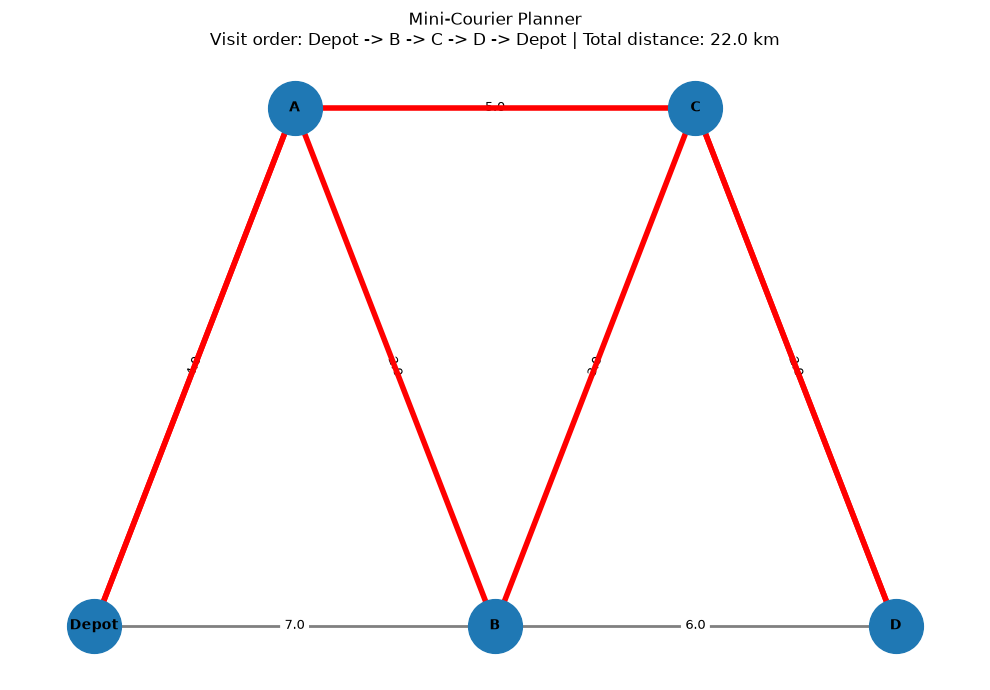

Route visualization saved to: c:\Users\Harsh Yadav\OneDrive\Documentos\Mini Courier Planner\images\route.png


In [7]:

# VISUALIZE THE COURIER ROAD NETWORK AND DELIVERY ROUTE

plt.figure(figsize=(10, 7))

# Create a NetworkX graph from our road data
road_graph = nx.Graph()

for _, road in roads.iterrows():
    road_graph.add_edge(
        road["From"],
        road["To"],
        weight=float(road["Distance"])
    )

# Use consistent positions for a readable map
positions = {
    "Depot": (0, 1),
    "A": (1, 2),
    "B": (2, 1),
    "C": (3, 2),
    "D": (4, 1)
}

# Draw all roads and locations
nx.draw_networkx_edges(
    road_graph, positions,
    edge_color="gray", width=2
)

nx.draw_networkx_nodes(
    road_graph, positions,
    node_size=1500
)

nx.draw_networkx_labels(
    road_graph, positions,
    font_size=10, font_weight="bold"
)

# Show distance on every road
edge_labels = nx.get_edge_attributes(road_graph, "weight")
nx.draw_networkx_edge_labels(
    road_graph, positions,
    edge_labels=edge_labels,
    font_size=9
)

# Highlight the delivery visit order
route_edges = [
    ("Depot", "B"),
    ("B", "C"),
    ("C", "D"),
    ("D", "Depot")
]

# These edges represent shortest-distance route legs.
# Some legs use multiple physical roads.
for start, end in route_edges:
    shortest_path = reconstruct_path(
        all_previous[start], start, end
    )
    path_edges = list(zip(shortest_path[:-1], shortest_path[1:]))

    nx.draw_networkx_edges(
        road_graph,
        positions,
        edgelist=path_edges,
        width=4,
        edge_color="red"
    )

plt.title(
    f"Mini-Courier Planner\n"
    f"Visit order: {' -> '.join(visit_order)} | "
    f"Total distance: {total_distance} km"
)
plt.axis("off")
plt.tight_layout()

# Save the image in the project's images folder
images_folder = PROJECT_DIR / "images"
images_folder.mkdir(parents=True, exist_ok=True)

route_image_path = images_folder / "route.png"
plt.savefig(route_image_path, dpi=200, bbox_inches="tight")
plt.show()

print("Route visualization saved to:", route_image_path)


In [8]:

# PHASE 4: RUNTIME PERFORMANCE TESTING

import random

random.seed(42)

def generate_test_parcels(size):
    """Generate sample parcels for performance testing."""
    test_parcels = []

    for i in range(size):
        test_parcels.append({
            "ParcelID": f"P{i}",
            "Priority": random.randint(1, 5),
            "Deadline": f"{random.randint(8, 17):02d}:00",
            "Weight": random.randint(1, 10),
            "Value": random.randint(10, 200),
            "Location": random.choice(["A", "B", "C", "D"])
        })

    return test_parcels

parcel_sizes = [10, 100, 500, 1000, 2000]
sorting_results = []

for size in parcel_sizes:
    test_data = generate_test_parcels(size)

    start_time = time.perf_counter()
    merge_sort_parcels(test_data)
    elapsed = time.perf_counter() - start_time

    sorting_results.append({
        "Number of Parcels": size,
        "Sorting Time (seconds)": elapsed
    })

sorting_results_df = pd.DataFrame(sorting_results)

print("MERGE SORT PERFORMANCE")
display(sorting_results_df.to_string(index=False))


MERGE SORT PERFORMANCE


' Number of Parcels  Sorting Time (seconds)\n                10                0.000049\n               100                0.000334\n               500                0.001412\n              1000                0.003219\n              2000                0.005765'

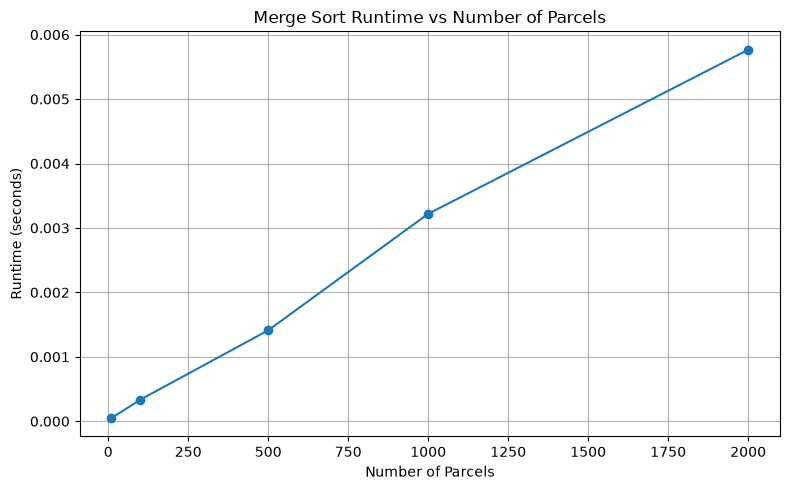

Runtime chart saved to: c:\Users\Harsh Yadav\OneDrive\Documentos\Mini Courier Planner\images\runtime_chart.png


In [9]:

# PLOT MERGE SORT PERFORMANCE

plt.figure(figsize=(8, 5))

plt.plot(
    sorting_results_df["Number of Parcels"],
    sorting_results_df["Sorting Time (seconds)"],
    marker="o"
)

plt.title("Merge Sort Runtime vs Number of Parcels")
plt.xlabel("Number of Parcels")
plt.ylabel("Runtime (seconds)")
plt.grid(True)
plt.tight_layout()

images_folder = PROJECT_DIR / "images"
images_folder.mkdir(parents=True, exist_ok=True)

runtime_chart_path = images_folder / "runtime_chart.png"
plt.savefig(runtime_chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("Runtime chart saved to:", runtime_chart_path)


In [10]:

# TEST KNAPSACK PERFORMANCE

knapsack_sizes = [10, 50, 100, 200, 500]
KNAPSACK_TEST_CAPACITY = 100
knapsack_results = []

for size in knapsack_sizes:
    test_data = generate_test_parcels(size)

    start_time = time.perf_counter()
    knapsack_dp(test_data, KNAPSACK_TEST_CAPACITY)
    elapsed = time.perf_counter() - start_time

    knapsack_results.append({
        "Number of Parcels": size,
        "Capacity": KNAPSACK_TEST_CAPACITY,
        "Runtime (seconds)": elapsed
    })

knapsack_results_df = pd.DataFrame(knapsack_results)

print("KNAPSACK PERFORMANCE")
display(knapsack_results_df.to_string(index=False))


KNAPSACK PERFORMANCE


' Number of Parcels  Capacity  Runtime (seconds)\n                10       100           0.000265\n                50       100           0.000988\n               100       100           0.001820\n               200       100           0.004568\n               500       100           0.008825'

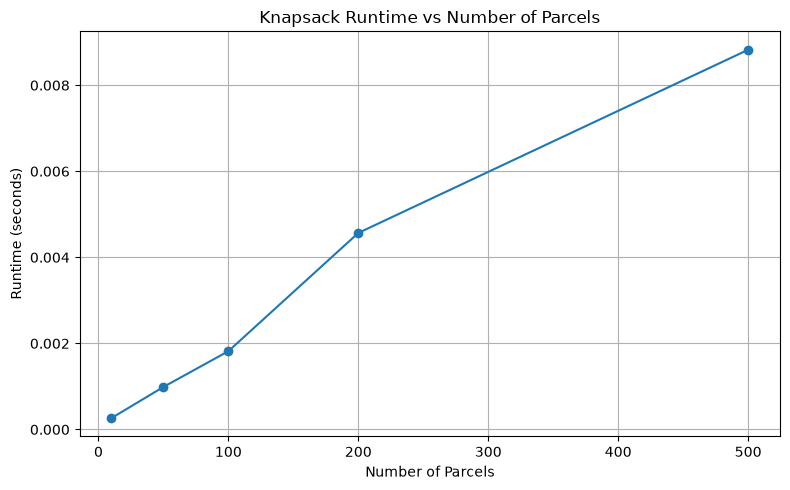

Knapsack chart saved to: c:\Users\Harsh Yadav\OneDrive\Documentos\Mini Courier Planner\images\knapsack_runtime.png


In [11]:

# PLOT KNAPSACK PERFORMANCE

plt.figure(figsize=(8, 5))

plt.plot(
    knapsack_results_df["Number of Parcels"],
    knapsack_results_df["Runtime (seconds)"],
    marker="o"
)

plt.title("Knapsack Runtime vs Number of Parcels")
plt.xlabel("Number of Parcels")
plt.ylabel("Runtime (seconds)")
plt.grid(True)
plt.tight_layout()

knapsack_chart_path = images_folder / "knapsack_runtime.png"
plt.savefig(knapsack_chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("Knapsack chart saved to:", knapsack_chart_path)
